# Dataset - ChurnSense

# Session 1 - Data Ingestion

In [79]:
# Ignoring the warnings. 

import warnings 
warnings.filterwarnings("ignore")

In [80]:
# Importing Pandas library. 

import pandas as pd

In [81]:
# Importing the dataset. 

cs = pd.read_csv(r"D:\AI_ML_DS Course_IIT Guwahati (Sept 2025-June 2026)\Internship Projects\01_ChurnSense\data\WA_Fn-UseC_-Telco-Customer-Churn.csv")
cs

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [82]:
# Printing the shape of the dataset. 

print("Shape of the dataset:", cs.shape)

Shape of the dataset: (7043, 21)


# Session 2 - EDA

In [83]:
# Checking the overview of the dataset. 

cs.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [84]:
# Converting the "TotalCharges" column to numeric, coercing errors to NaN.

cs["TotalCharges"] = pd.to_numeric(cs["TotalCharges"], errors = "coerce")

In [85]:
# Checking the number of NaN values in the "TotalCharges" column.

cs["TotalCharges"].isnull().sum()

np.int64(11)

In [86]:
# Filling the NaN values in the "TotalCharges" column with the median of the column.

cs["TotalCharges"] = cs["TotalCharges"].fillna(cs["TotalCharges"].median())

In [87]:
# Checking the distribution of target variable "Churn" in the dataset. 

print(cs["Churn"].value_counts())
print((cs["Churn"].value_counts(normalize = True) * 100).round(2))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [88]:
# Importing matplotlib and seaborn libraries for visualization.

import matplotlib.pyplot as plt
import seaborn as sns

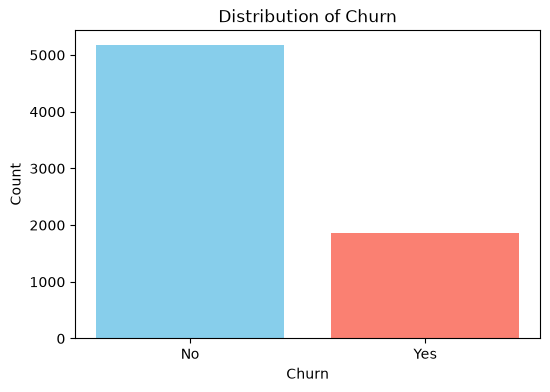

In [89]:
# Plotting the bar chart for the distribution of target variable "Churn" in the dataset.

plt.figure(figsize = (6, 4))
plt.bar(cs["Churn"].value_counts().index, cs["Churn"].value_counts().values, color = ["skyblue", "salmon"]) # .index gives the category names (No and Yes) on the X-axis, and .values() gives the category counts (5174 and 1869) on the Y-axis. 
plt.xlabel("Churn")
plt.ylabel("Count")
plt.title("Distribution of Churn")
plt.show()

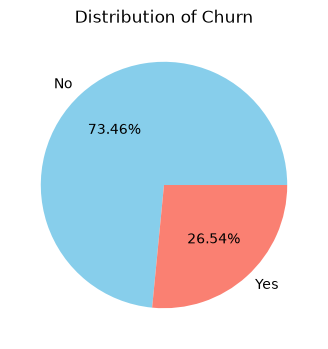

In [90]:
# Plotting the pie chart for the distribution of target variable "Churn" in the dataset.

plt.figure(figsize = (6, 4))
plt.pie(cs["Churn"].value_counts().values, labels = cs["Churn"].value_counts().index, autopct = "%1.2f%%", colors = ["skyblue", "salmon"])
plt.title("Distribution of Churn")
plt.show()

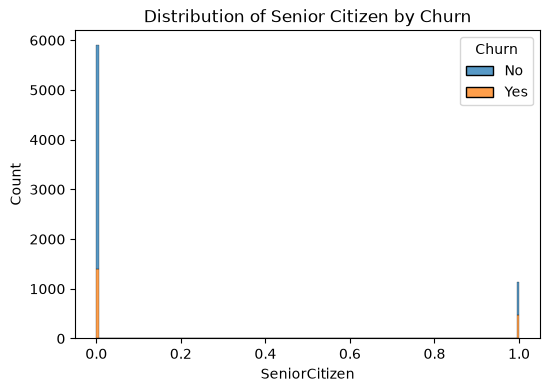

In [91]:
# Relationship between "Churn" and each numerical feature in the dataset using histograms. 
# "Churn" and "SeniorCitizen"

plt.figure(figsize = (6, 4))
sns.histplot(data = cs, x = "SeniorCitizen", hue = "Churn", multiple = "stack")
plt.title("Distribution of Senior Citizen by Churn")
plt.show()

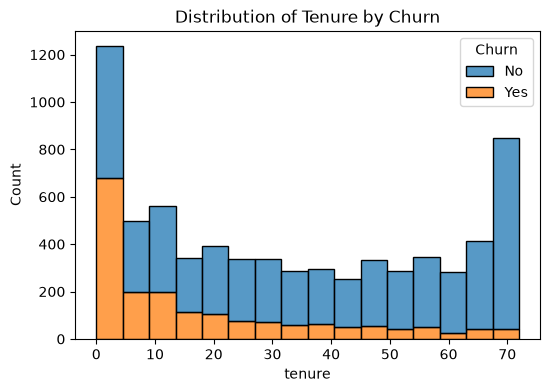

In [92]:
# "Churn" and "tenure"

plt.figure(figsize = (6, 4))
sns.histplot(data = cs, x = "tenure", hue = "Churn", multiple = "stack")
plt.title("Distribution of Tenure by Churn")
plt.show()

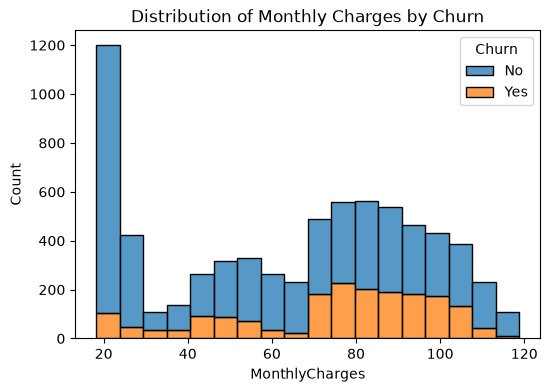

In [93]:
# "Churn" and "MonthlyCharges"

plt.figure(figsize = (6, 4))
sns.histplot(data = cs, x = "MonthlyCharges", hue = "Churn", multiple = "stack")
plt.title("Distribution of Monthly Charges by Churn")
plt.show()

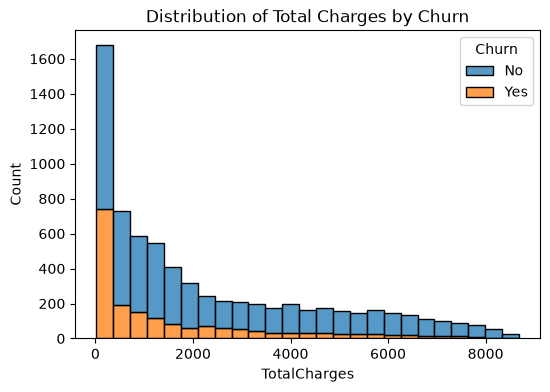

In [94]:
# "Churn" and "TotalCharges"

plt.figure(figsize = (6, 4))
sns.histplot(data = cs, x = "TotalCharges", hue = "Churn", multiple = "stack")
plt.title("Distribution of Total Charges by Churn")
plt.show()

In [95]:
# Churn rate per categorical feature. 
# Using Pandas .groupby() function
# "Churn" and "Contract"

cs.groupby(["Contract", "Churn"]).size()

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
dtype: int64

In [96]:
# "Churn" and "gender"

cs.groupby(["gender", "Churn"]).size()

gender  Churn
Female  No       2549
        Yes       939
Male    No       2625
        Yes       930
dtype: int64

In [97]:
# Encoding "No" to 0 and "Yes" to 1 in the target variable "Churn" using Pandas .replace() function.

cs["Churn"] = cs["Churn"].replace({"No": 0, "Yes": 1})
cs["Churn"] = pd.to_numeric(cs["Churn"])

In [98]:
# Computing the correlation among all the numerical features in the dataset. 

for col in cs.columns:
    if cs[col].dtype in ["int64", "float64"]: # Here, "in" is a membership operator. 
        correlation = cs[col].corr(cs["Churn"]) # Calculates the Pearson correlation. 
        print(col, correlation.round(4))

SeniorCitizen 0.1509
tenure -0.3522
MonthlyCharges 0.1934
TotalCharges -0.199
Churn 1.0


In [99]:
# Printing the correlation matrix. 

correlation_matrix = cs.corr(numeric_only = True)
print(correlation_matrix) 

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges  \
SeniorCitizen        1.000000  0.016567        0.220173      0.102652   
tenure               0.016567  1.000000        0.247900      0.825464   
MonthlyCharges       0.220173  0.247900        1.000000      0.650864   
TotalCharges         0.102652  0.825464        0.650864      1.000000   
Churn                0.150889 -0.352229        0.193356     -0.199037   

                   Churn  
SeniorCitizen   0.150889  
tenure         -0.352229  
MonthlyCharges  0.193356  
TotalCharges   -0.199037  
Churn           1.000000  


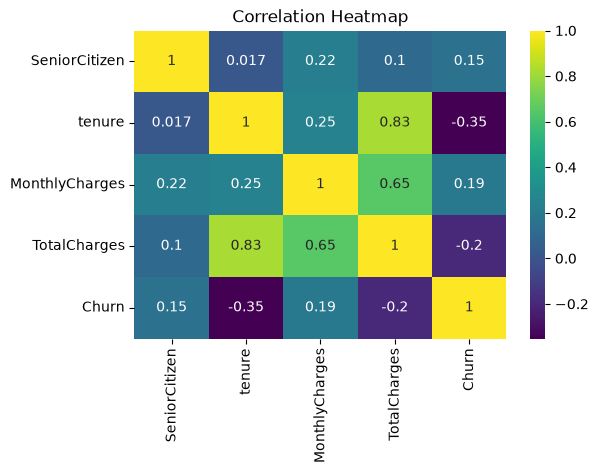

In [100]:
# Creating a correlation heatmap. 

plt.figure(figsize = (6, 4))
sns.heatmap(correlation_matrix, annot = True, cmap = "viridis")
plt.title("Correlation Heatmap")
plt.show()

# Session 3 - Preprocessing and Feature Engineering

In [101]:
# Dropping irrelevant features from the dataset - "customerID". 

cs.drop(columns = ["customerID"], inplace = True)

In [102]:
# Separating the features (X) and target variable (y) from the dataset.
# X 

X = cs.drop(columns = ["Churn"]) 
X

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60


In [103]:
# y

y = cs["Churn"]
y

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [104]:
# Storing numerical features in a separate variable. 

num_features = X.select_dtypes(include = ["int64", "float64"]).columns  

In [105]:
# Storing categorical features in a separate variable. 

cat_features = X.select_dtypes(include = ["object"]).columns 

In [106]:
# Feature engineering 
# Importing ColumnTransformer, StandardScaler and OneHotEncoder (OHE)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [107]:
preprocessor = ColumnTransformer([
    ("sc", StandardScaler(), num_features),
    ("OHE", OneHotEncoder(handle_unknown = "ignore", sparse_output = False), cat_features) # handle_unknown = "ignore" handles previously unseen categories (features) by assigning zeros to their encoded columns. sparse_output = False returns a dense NumPy array.
])

In [108]:
# Importing train_test_split. 

from sklearn.model_selection import train_test_split

In [109]:
# Splitting the dataset into train and test. 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y) # stratify = y means the target variable is imbalanced. Therefore, it maintains the same proportion of each "target class" (here, No and Yes) in both the datasets, train and test. 
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5634, 19), (1409, 19), (5634,), (1409,))

In [110]:
# Creating 3 new columns - tenure_group (using bins), monthly_per_tenure_ratio, num_services. 
# tenure_group (using bins)

X["tenure_group"] = pd.cut(X["tenure"], bins = [-1, 12, 24, 36, 48, 60, 72], labels = ["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"]) 

# By default, pd.cut() uses bins (intervals) that exclude the left boundary and include the right boundary. Starting at -1 ensures that a customer with tenure = 0 is included in the first group. 

In [111]:
# monthly_per_tenure_ratio

X["monthly_per_tenure_ratio"] = X["MonthlyCharges"] / X["tenure"].replace(0, float("nan")) # .replace(0, float("nan") is used to avoid zero-division error.  

In [112]:
# num_services 
# Firstly, creating a variable storing all the services. 

service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"] # "InternetService" is not being considered because it has distinct values - "DSL", "Fiber optic", and "No". In contrast, other service-related features have "No", "Yes", and "No internet service". 

# Session 4 - Model Building

In [113]:
# Importing ML models - Logistic Regression (LR), Decision Tree (DT), Random Forest (RF), Gradient Boost (GB), and XGBoost (XGB).

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

In [114]:
# Defining ML models. 

models = {
    "LR": LogisticRegression(penalty = "l2", C = 1.0, solver = "lbfgs", max_iter = 1000, class_weight = "balanced", random_state = 42, n_jobs = -1, verbose = 0),
    "DT": DecisionTreeClassifier(max_depth = 5, min_samples_split = 10, min_samples_leaf = 2, max_features = None, class_weight = "balanced", random_state = 42),
    "RF": RandomForestClassifier(n_estimators = 200, max_depth = 5, min_samples_split = 10, min_samples_leaf = 2, max_features = "sqrt", class_weight = "balanced", random_state = 42, n_jobs = -1),
    "GB": GradientBoostingClassifier(n_estimators = 100, learning_rate = 0.1, max_depth = 3, min_samples_split = 10, min_samples_leaf = 2, max_features = None, subsample = 1.0, random_state = 42, verbose = 0),
    "XGB": XGBClassifier(n_estimators = 200, learning_rate = 0.1, max_depth = 3, min_child_weight = 2, subsample = 0.8, colsample_bytree = 0.8, reg_alpha = 0, reg_lambda = 1, eval_metric = "logloss", random_state = 42, n_jobs = -1, verbose = 0)   
}

models

{'LR': LogisticRegression(class_weight='balanced', max_iter=1000, n_jobs=-1,
                    penalty='l2', random_state=42),
 'DT': DecisionTreeClassifier(class_weight='balanced', max_depth=5, min_samples_leaf=2,
                        min_samples_split=10, random_state=42),
 'RF': RandomForestClassifier(class_weight='balanced', max_depth=5, min_samples_leaf=2,
                        min_samples_split=10, n_estimators=200, n_jobs=-1,
                        random_state=42),
 'GB': GradientBoostingClassifier(min_samples_leaf=2, min_samples_split=10,
                            random_state=42),
 'XGB': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=0.8, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric='logloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=No

In [115]:
# Importing Pipeline.

from sklearn.pipeline import Pipeline 

In [116]:
# Storing feature preprocessing and models in a dictionary named pipelines. 

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline([
        ("prep", preprocessor), # "prep" is the name given to the preprocessor and "model" is the name given to the model. 
        ("model", model) 
    ]) 

In [117]:
# Importing stratified K fold (SKF), cross-validation (CV) score, classification report, ROC-AUC score, and confusion matrix.  

from sklearn.model_selection import StratifiedKFold, cross_val_score 
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix

In [118]:
# Running SKF.

skf = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42) 

In [119]:
# Running CV with 5-fold SKF and using "ROC-AUC" score as the scoring metric. This is because the target variable in the dataset is imbalanced; hence, accuracy can be misleading.  

cv = cross_val_score(pipelines[name], X_train, y_train, cv = skf, scoring = "roc_auc") 

In [120]:
# Storing the metrics in a list named results. 

results = []

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_pred_proba = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name, 
        "ROC-AUC": roc_auc_score(y_test, y_pred_proba),
        "F1 Score": f1_score(y_test, y_pred),
        "Precision Score": precision_score(y_test, y_pred),
        "Recall Score": recall_score(y_test, y_pred)
    }) 

results

[{'Model': 'LR',
  'ROC-AUC': 0.8412978893797307,
  'F1 Score': 0.6136125654450262,
  'Precision Score': 0.504302925989673,
  'Recall Score': 0.7834224598930482},
 {'Model': 'DT',
  'ROC-AUC': 0.8317988064791133,
  'F1 Score': 0.6206140350877193,
  'Precision Score': 0.5260223048327137,
  'Recall Score': 0.7566844919786097},
 {'Model': 'RF',
  'ROC-AUC': 0.8391110594435403,
  'F1 Score': 0.614900314795383,
  'Precision Score': 0.5060449050086355,
  'Recall Score': 0.7834224598930482},
 {'Model': 'GB',
  'ROC-AUC': 0.8443346508563899,
  'F1 Score': 0.5964391691394659,
  'Precision Score': 0.67,
  'Recall Score': 0.5374331550802139},
 {'Model': 'XGB',
  'ROC-AUC': 0.8437546823736083,
  'F1 Score': 0.5925925925925926,
  'Precision Score': 0.6644518272425249,
  'Recall Score': 0.5347593582887701}]

In [121]:
# Creating a DataFrame summarizing the results. 

results_df = pd.DataFrame(results)
print(results_df)

  Model   ROC-AUC  F1 Score  Precision Score  Recall Score
0    LR  0.841298  0.613613         0.504303      0.783422
1    DT  0.831799  0.620614         0.526022      0.756684
2    RF  0.839111  0.614900         0.506045      0.783422
3    GB  0.844335  0.596439         0.670000      0.537433
4   XGB  0.843755  0.592593         0.664452      0.534759


#### From the above output, we can conclude that DT yields the best F1 score. Therefore, we will print the classification report for DT. 

In [122]:
# Getting the DT pipeline from pipelines[name]. 

DT_pipeline = pipelines["DT"]

In [123]:
# Evaluating the DT_pipeline on X_test and predicting y. 

y_pred_DT = DT_pipeline.predict(X_test)

In [124]:
# Printing the classification report for DT. 

print("Classification Report for DT:", classification_report(y_test, y_pred_DT))

Classification Report for DT:               precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



# Session 5 - Evaluation and Model Selection

In [125]:
# Importing ROC curve. 

from sklearn.metrics import roc_curve

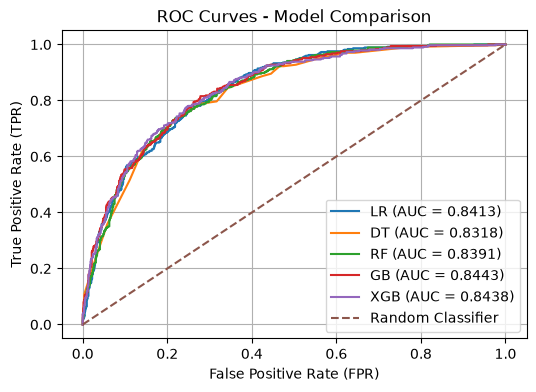

In [126]:
plt.figure(figsize=(6, 4))

for name, pipeline in pipelines.items():

    # Training the pipeline.
    pipeline.fit(X_train, y_train)

    # Predicting probabilities for Churn = Yes.
    y_pred_proba = pipeline.predict_proba(X_test)[:, 1]

    # Computing ROC curve values.
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

    # Computing ROC-AUC score.
    auc_value = roc_auc_score(y_test, y_pred_proba)

    # Plotting each model's ROC curve.
    plt.plot(fpr, tpr, label = f"{name} (AUC = {auc_value:.4f})")

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle = "--", label = "Random Classifier")

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curves - Model Comparison")
plt.legend()
plt.grid()
plt.show()

#### The top 2 models are DT and RF, based on their F1 scores. 

In [127]:
cm_DT = confusion_matrix(y_test, y_pred_DT)
print(cm_DT)

[[780 255]
 [ 91 283]]


In [128]:
import matplotlib.pyplot as plt
import seaborn as sns

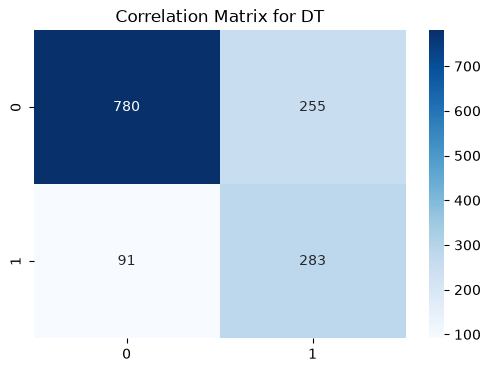

In [129]:
plt.figure(figsize = (6, 4))
sns.heatmap(cm_DT, annot = True, cmap = "Blues", fmt = "d")
plt.title("Correlation Matrix for DT")
plt.show()

In [130]:
# Getting the RF pipeline from pipelines[name]. 

RF_pipeline = pipelines["RF"]

In [131]:
y_pred_RF = RF_pipeline.predict(X_test)

In [132]:
cm_RF = confusion_matrix(y_test, y_pred_RF)
print(cm_RF)

[[749 286]
 [ 81 293]]


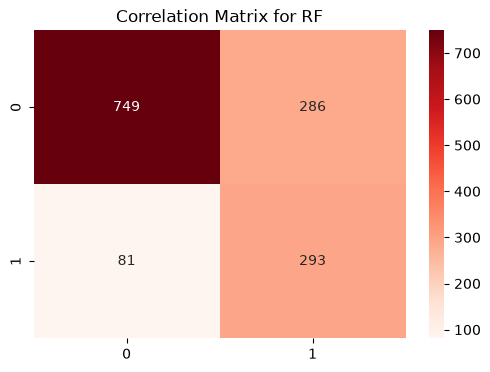

In [133]:
plt.figure(figsize = (6, 4))
sns.heatmap(cm_RF, annot = True, cmap = "Reds", fmt = "d")
plt.title("Correlation Matrix for RF")
plt.show()

In [134]:
# Importing RandomizedSearchCV. 

from sklearn.model_selection import RandomizedSearchCV

In [135]:
# Hyperparameter tuning for the DT model. 

param_dist_DT = {
    "model__max_depth": [None, 3, 5, 7, 10],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": [None, "sqrt", "log2"]
}

random_search_DT = RandomizedSearchCV(estimator = DT_pipeline, param_distributions = param_dist_DT, n_iter = 20, cv = skf, scoring = "f1", n_jobs = -1, verbose = 1, random_state = 42)

random_search_DT.fit(X_train, y_train)

random_search_DT.best_params_

random_search_DT.best_score_

best_DT_model = random_search_DT.best_estimator_

random_search_DT_tuned = best_DT_model.predict(X_test)

print("F1 Score of the Tuned DT Model on the Test Dataset:", f1_score(y_test, random_search_DT_tuned))  

Fitting 5 folds for each of 20 candidates, totalling 100 fits
F1 Score of the Tuned DT Model on the Test Dataset: 0.6212952799121844


In [136]:
# Hyperparameter tuning for the RF model. 

param_dist_RF = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 3, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": [None, "sqrt", "log2"]
}

random_search_RF = RandomizedSearchCV(estimator = RF_pipeline, param_distributions = param_dist_RF, n_iter = 20, cv = skf, scoring = "f1", n_jobs = -1, verbose = 1, random_state = 42)

random_search_RF.fit(X_train, y_train)

random_search_RF.best_params_

random_search_RF.best_score_

best_RF_model = random_search_RF.best_estimator_

random_search_RF_tuned = best_RF_model.predict(X_test)

print("F1 Score of the Tuned RF Model on the Test Dataset:", f1_score(y_test, random_search_RF_tuned))  

Fitting 5 folds for each of 20 candidates, totalling 100 fits
F1 Score of the Tuned RF Model on the Test Dataset: 0.6310160427807486


In [137]:
# Transforming X_test. 

preprocessor = pipelines["RF"].named_steps["prep"]

X_test_transformed = preprocessor.transform(X_test) # X_test_transformed is (1409, 45) meaning there are 1409 customers (rows) and 45 features (columns). 

In [138]:
# Extracting the best model, RF.

RF_model = RF_pipeline.named_steps["model"]

In [139]:
# Importing SHAP.

import shap

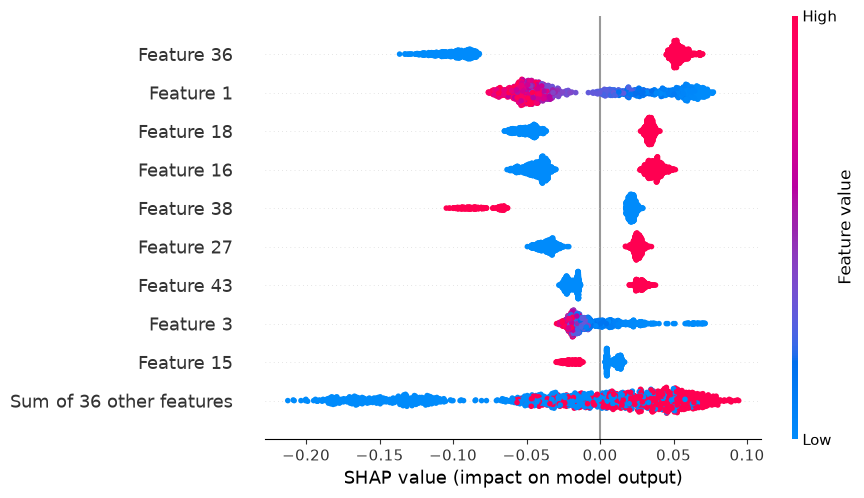

In [140]:
# SHAP feature importance. 

explainer = shap.TreeExplainer(RF_model)

shap_values = explainer(X_test_transformed)

shap.plots.beeswarm(shap_values[:, :, 1]) # First : selects all test customers, second : selects all 45 features, and 1 selects the model's output for class 1 (Churn), assuming class order is [0, 1]. 

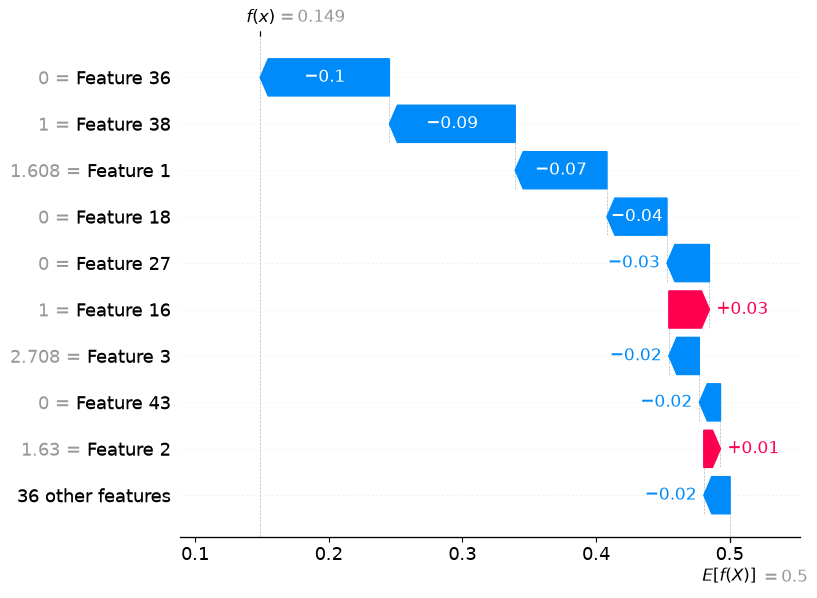

In [141]:
# Waterfall plot for the first customer where churn was predicted (i.e., "Yes"). 

shap.plots.waterfall(shap_values[0, :, 1]) # 0 means first customer, : means all features (45), and 1 means churn class ("Yes"). 

In [142]:
# Importing joblib. 

import joblib 

In [143]:
# Saving the final model. 

joblib.dump(RF_pipeline, "churn_model_v1.pkl")

['churn_model_v1.pkl']

In [144]:
# Loading the saved model. 

loaded = joblib.load("churn_model_v1.pkl")
loaded.predict(X_test[:3]) # Predicts the churn labels for the first 3 test samples. 

array([0, 1, 0])